# 02 - How the data is checked and processed

The path from the raw TLC file to the model's input, step by step, with the real counts for
January 2025. The code is in `src/data.py` (cleaning), `src/checks.py` (rules) and
`src/features.py` (features); training calls `checks.assert_clean` and stops if a rule fails.

In [1]:
import os
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src import checks, data
from src.features import FEATURES, build_features

raw = data.load()
print(f"Step 0 - raw file: {len(raw):,} trips, {raw.shape[1]} columns")
print("columns used:", checks.REQUIRED_COLUMNS)

Step 0 - raw file: 3,475,226 trips, 20 columns
columns used: ['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'PULocationID', 'DOLocationID', 'trip_distance']


## Step 1 - Check the raw data against the rules

Each rule counts the trips that break it. A trip can break more than one rule.

In [2]:
raw_report = checks.report(raw)
raw_report

,rule,failing_rows,failing_pct
0,pickup or dropoff time missing,0,0.000
1,pickup or dropoff zone missing,0,0.000
2,zone outside 1-265,0,0.000
3,dropoff not after pickup,2051,0.059
4,duration under 1 minute,38060,1.095
5,duration over 60 minutes,31867,0.917
6,distance 0 or negative,90893,2.615
7,distance over 100 miles,162,0.005
8,pickup outside the month,22,0.001


## Step 2 - Clean: add the target and drop impossible trips

`data.clean` computes `duration = dropoff - pickup` in minutes, then keeps trips of 1-60 minutes,
distance above 0 and at most 100 miles, with the pickup inside January.

In [3]:
duration = (raw.tpep_dropoff_datetime - raw.tpep_pickup_datetime).dt.total_seconds() / 60
steps = [
    ("raw file", pd.Series(True, index=raw.index)),
    ("+ duration 1-60 min", duration.between(1, 60)),
    ("+ distance > 0", raw.trip_distance > 0),
    ("+ distance <= 100", raw.trip_distance <= 100),
    ("+ pickup in January", (raw.tpep_pickup_datetime >= "2025-01-01") & (raw.tpep_pickup_datetime < "2025-02-01")),
]
keep = pd.Series(True, index=raw.index)
funnel = []
for name, mask in steps:
    keep &= mask
    funnel.append({"step": name, "trips left": int(keep.sum()), "share of raw": f"{keep.mean():.1%}"})
pd.DataFrame(funnel)

,step,trips left,share of raw
0,raw file,3475226,100.0%
1,+ duration 1-60 min,3403248,97.9%
2,+ distance > 0,3339226,96.1%
3,+ distance <= 100,3339105,96.1%
4,+ pickup in January,3339084,96.1%


## Step 3 - Check the cleaned data: every rule must show 0 failures

In [4]:
clean = data.clean(raw)
display(checks.report(clean))
checks.assert_clean(clean)
print("assert_clean passed: training may use this data")

,rule,failing_rows,failing_pct
0,pickup or dropoff time missing,0,0.0
1,pickup or dropoff zone missing,0,0.0
2,zone outside 1-265,0,0.0
3,dropoff not after pickup,0,0.0
4,duration under 1 minute,0,0.0
5,duration over 60 minutes,0,0.0
6,distance 0 or negative,0,0.0
7,distance over 100 miles,0,0.0
8,pickup outside the month,0,0.0


assert_clean passed: training may use this data


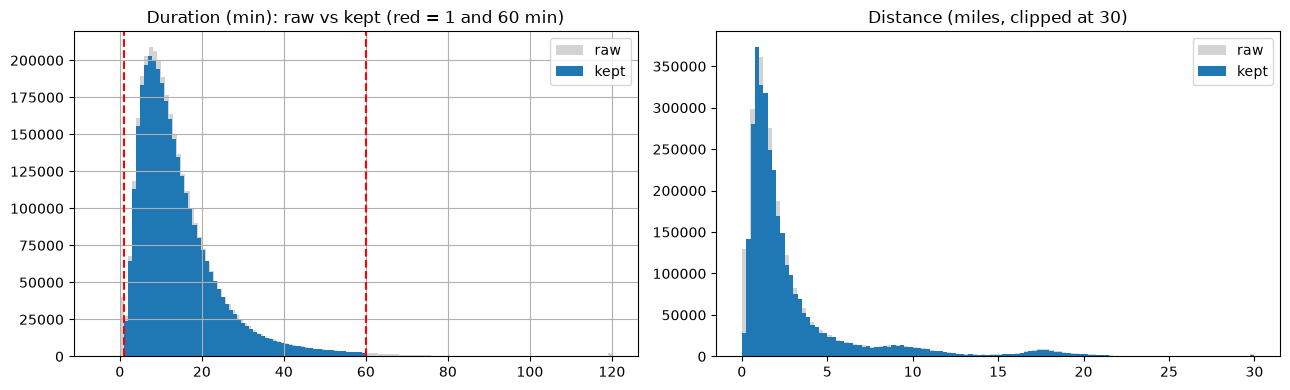

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
duration.clip(-5, 120).hist(bins=125, ax=axes[0], color="lightgray", label="raw")
clean[data.TARGET].hist(bins=60, ax=axes[0], color="tab:blue", label="kept")
axes[0].axvline(1, color="red", ls="--"); axes[0].axvline(60, color="red", ls="--")
axes[0].set_title("Duration (min): raw vs kept (red = 1 and 60 min)"); axes[0].legend()
axes[1].hist(raw.trip_distance.clip(0, 30), bins=120, color="lightgray", label="raw")
axes[1].hist(clean.trip_distance.clip(0, 30), bins=120, color="tab:blue", label="kept")
axes[1].set_title("Distance (miles, clipped at 30)"); axes[1].legend(); plt.tight_layout()

## Step 4 - Build the features

Only what is known when a trip starts. Fare, tip and total amount are recorded after the trip,
so using them would leak the answer.

In [6]:
X = build_features(clean)
example = pd.concat([clean[["tpep_pickup_datetime", "PULocationID", "DOLocationID", "trip_distance", data.TARGET]].head(3),
                     X[["pickup_hour", "pickup_weekday"]].head(3)], axis=1)
print("features:", FEATURES)
example

features: ['PULocationID', 'DOLocationID', 'trip_distance', 'pickup_hour', 'pickup_weekday']


,tpep_pickup_datetime,PULocationID,DOLocationID,trip_distance,duration,pickup_hour,pickup_weekday
0,2025-01-01 00:18:38,229,237,1.6,8.35,0,2
1,2025-01-01 00:32:40,236,237,0.5,2.55,0,2
2,2025-01-01 00:44:04,141,141,0.6,1.95,0,2


## Step 5 - Split

80/20 split with seed 42. Model comparisons train on a 500,000-row sample of the 80% (fast and
fair); the served model trains on all 2,671,267 rows, because the learning curve in notebook 03
shows more data still helps. The 20% (667,817 trips) is never used for training.

In [7]:
from src.train import load_split
X_train, X_val, y_train, y_val, n_clean = load_split(500_000)
print(f"clean {n_clean:,} -> train sample {len(X_train):,} | validation {len(X_val):,}")
print(f"target mean: train {y_train.mean():.2f} min, validation {y_val.mean():.2f} min")

clean 3,339,084 -> train sample 500,000 | validation 667,817
target mean: train 14.18 min, validation 14.22 min


## Step 6 - Does next month look the same? (a simple drift check)

The model is also scored on February 2025. Before that, compare the data itself.

In [8]:
feb = data.clean(data.load(data.download(2025, 2)), year=2025, month=2)
checks.assert_clean(feb, year=2025, month=2)
drift = pd.DataFrame({"January": checks.summary(clean), "February": checks.summary(feb)})
drift["change"] = (drift["February"] - drift["January"]).round(3)
drift

,January,February,change
rows,3339084.000,3427258.000,88174.000
duration_median,11.670,12.170,0.500
distance_median,1.700,1.750,0.050
rush_hour_share,0.316,0.305,-0.011
weekend_share,0.258,0.302,0.044
airport_pickup_share,0.064,0.055,-0.009
